In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bat_hd.plot_tools import angular_error, smooth_ts
import os

plt.rcParams.update(
    {
        "font.family": "Helvetica",
        "font.size": 12,
    }
)

DATA_DIR = "../simulation_data/comparison"
PLOTS_DIR = "../plots/comparison"

In [2]:
config_names = set()
for file in os.listdir(DATA_DIR):
    if file.endswith(".npz"):
        if "recording_" in file:
            config_name = "_".join(file.split("recording_")[1].split("_")[:-1])
            config_names.add(config_name)

seeds = set()
for file in os.listdir(DATA_DIR):
    if file.endswith(".npz"):
        if "bat_flight_" in file:
            seed = int(file.split("bat_flight_")[1].split(".")[0])

            if all(
                os.path.exists(
                    os.path.join(DATA_DIR, f"recording_{config_name}_{seed}.npz")
                )
                for config_name in config_names
            ):
                seeds.add(seed)

seeds = sorted(list(seeds))
bat_flights = [
    np.load(os.path.join(DATA_DIR, f"bat_flight_{seed}.npz")) for seed in seeds
]
recordings = {
    " ".join(map(lambda x: x.capitalize(), config_name.split("_"))): [
        np.load(os.path.join(DATA_DIR, f"recording_{config_name}_{seed}.npz"))
        for seed in seeds
    ]
    for config_name in config_names
}

In [3]:
def compute_error(bat_flight, recording):
    """
    Compute the angular error between the true bat flight and the decoded flight from the recording.
    """
    true_yaw = bat_flight["dir_torus"][:, 0]
    true_pitch = bat_flight["dir_torus"][:, 1]
    decoded_yaw = recording["decoded_angle"][:, 0]
    decoded_pitch = recording["decoded_angle"][:, 1]
    interval = recording.get("inveral", None)
    if interval is None:
        interval = len(true_yaw) // len(decoded_yaw)
    true_yaw = true_yaw[::interval]
    true_pitch = true_pitch[::interval]

    yaw_error = np.abs(angular_error(decoded_yaw, true_yaw))
    pitch_error = np.abs(angular_error(decoded_pitch, true_pitch))

    return yaw_error, pitch_error

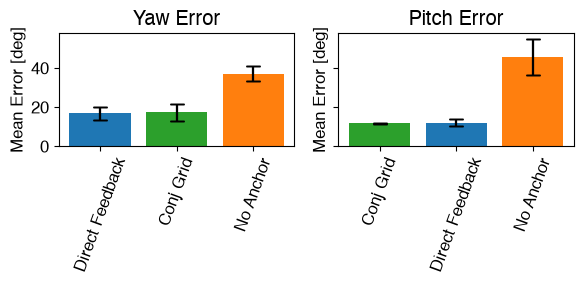

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(6, 3), sharey=True)
for config_name, recording_list in recordings.items():
    all_yaw_errors = []
    all_pitch_errors = []
    for seed, (bat_flight, recording) in enumerate(zip(bat_flights, recording_list)):
        yaw_error, pitch_error = compute_error(bat_flight, recording)
        all_yaw_errors.append(np.mean(yaw_error))
        all_pitch_errors.append(np.mean(pitch_error))

    results = []

    for config_name, recording_list in recordings.items():
        all_yaw_errors = []
        all_pitch_errors = []

        for bat_flight, recording in zip(bat_flights, recording_list):
            yaw_error, pitch_error = compute_error(bat_flight, recording)
            all_yaw_errors.append(np.mean(yaw_error))
            all_pitch_errors.append(np.mean(pitch_error))

        results.append(
            (
                config_name,
                np.mean(all_yaw_errors),
                np.std(all_yaw_errors) / np.sqrt(len(seeds)),
                np.mean(all_pitch_errors),
                np.std(all_pitch_errors) / np.sqrt(len(seeds)),
            )
        )

    colors = plt.cm.tab10(np.arange(len(results)))

    yaw_results = sorted(results, key=lambda x: x[1])
    pitch_results = sorted(results, key=lambda x: x[3])
    color_by_config = {result[0]: color for result, color in zip(results, colors)}

    for axis, sorted_results, title in zip(
        ax,
        (yaw_results, pitch_results),
        ("Yaw Error", "Pitch Error"),
    ):
        labels = [result[0] for result in sorted_results]
        means = [
            result[1 if title.startswith("Yaw") else 3] for result in sorted_results
        ]
        errors = [
            result[2 if title.startswith("Yaw") else 4] for result in sorted_results
        ]
        sorted_colors = [color_by_config[label] for label in labels]

        axis.bar(labels, means, yerr=errors, capsize=5, color=sorted_colors)
        axis.set_title(title)
        axis.tick_params(axis="x", rotation=70)

        axis.set_ylabel(r"Mean Error [deg]")

fig.tight_layout()
fig.savefig(
    os.path.join(PLOTS_DIR, "angular_error_comparison.pdf"), bbox_inches="tight"
)